# BÀI 2: Mua sắm của khách hàng Mall customer


## Chuẩn bị thư viện

In [9]:
print("NguyenDucTinh - 6451071077")

# Thư viện xử lý dữ liệu
import numpy as np
import pandas as pd

# Thư viện trực quan hóa dữ liệu
import matplotlib.pyplot as plt
import seaborn as sns

# Thư viện xây dựng mô hình K-Means
from sklearn.cluster import KMeans

# Thư viện đánh giá mô hình
from sklearn import metrics
from sklearn.metrics import silhouette_score

# Thư viện vẽ biểu đồ 3D
import plotly.graph_objects as go
import plotly.offline as py

# Cấu hình hiển thị biểu đồ
%matplotlib inline

# Cấu hình giao diện biểu đồ
sns.set_style("whitegrid")

# Hiển thị đầy đủ các cột dữ liệu
pd.set_option('display.max_columns', None)

print("Đã import tất cả thư viện thành công!")

NguyenDucTinh - 6451071077
Đã import tất cả thư viện thành công!


## Câu 1: Đọc dữ liệu, thống kê và xử lý dữ liệu thiếu

1.1 Đọc dữ liệu

In [10]:
print("NguyenDucTinh - 6451071077")

# Đọc dữ liệu từ file CSV
data = pd.read_csv('Mall_Customers.csv')

# Loại bỏ khoảng trắng thừa trong tên cột
data.columns = data.columns.str.strip()

# Hiển thị 5 dòng dữ liệu đầu tiên
print("5 dòng dữ liệu đầu tiên:")
display(data.head())

# Hiển thị 5 dòng dữ liệu cuối cùng
print("5 dòng dữ liệu cuối cùng:")
display(data.tail())

# Hiển thị kích thước dữ liệu
print("\nKích thước dữ liệu:")
print(data.shape)

# Hiển thị thông tin các thuộc tính
print("\nThông tin dữ liệu:")
data.info()

NguyenDucTinh - 6451071077
5 dòng dữ liệu đầu tiên:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


5 dòng dữ liệu cuối cùng:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83



Kích thước dữ liệu:
(200, 5)

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


1.2 Thống kê và xử lý dữ liệu thiếu

In [11]:
print("NguyenDucTinh - 6451071077")

# Thống kê các giá trị thống kê cơ bản
print("Thống kê dữ liệu:")
display(data.describe())

# Thống kê các thuộc tính dạng phân loại
print("\nThống kê thuộc tính Gender:")
display(data['Gender'].value_counts())

# Kiểm tra dữ liệu bị thiếu
print("\nSố lượng giá trị thiếu của từng cột:")
print(data.isnull().sum())

# Kiểm tra tổng số giá trị thiếu
print("\nTổng số giá trị thiếu:")
print(data.isnull().sum().sum())

# Xử lý dữ liệu thiếu
# Các cột số: thay thế bằng giá trị trung vị
for column in data.select_dtypes(include=np.number).columns:
    data[column] = data[column].fillna(data[column].median())

# Các cột dạng phân loại: thay thế bằng giá trị xuất hiện nhiều nhất
for column in data.select_dtypes(include='object').columns:
    data[column] = data[column].fillna(data[column].mode()[0])

# Xóa các dòng dữ liệu trùng lặp
data.drop_duplicates(inplace=True)

# Kiểm tra lại dữ liệu sau xử lý
print("\nSố lượng giá trị thiếu sau xử lý:")
print(data.isnull().sum())

print("\nKích thước dữ liệu sau xử lý:")
print(data.shape)

print("\nDữ liệu sau xử lý:")
display(data.head())

NguyenDucTinh - 6451071077
Thống kê dữ liệu:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Thống kê thuộc tính Gender:


Gender
Female    112
Male       88
Name: count, dtype: int64


Số lượng giá trị thiếu của từng cột:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Tổng số giá trị thiếu:
0

Số lượng giá trị thiếu sau xử lý:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Kích thước dữ liệu sau xử lý:
(200, 5)

Dữ liệu sau xử lý:


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17000\4077456479.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in data.select_dtypes(include='object').columns:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Câu 2: Biểu diễn phân phối dữ liệu bằng Histogram

NguyenDucTinh - 6451071077


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17000\1320041493.py:16: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data[x], bins=20)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17000\1320041493.py:16: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data[x], bins=20)
C:\Users\LENOVO\AppData\Local\

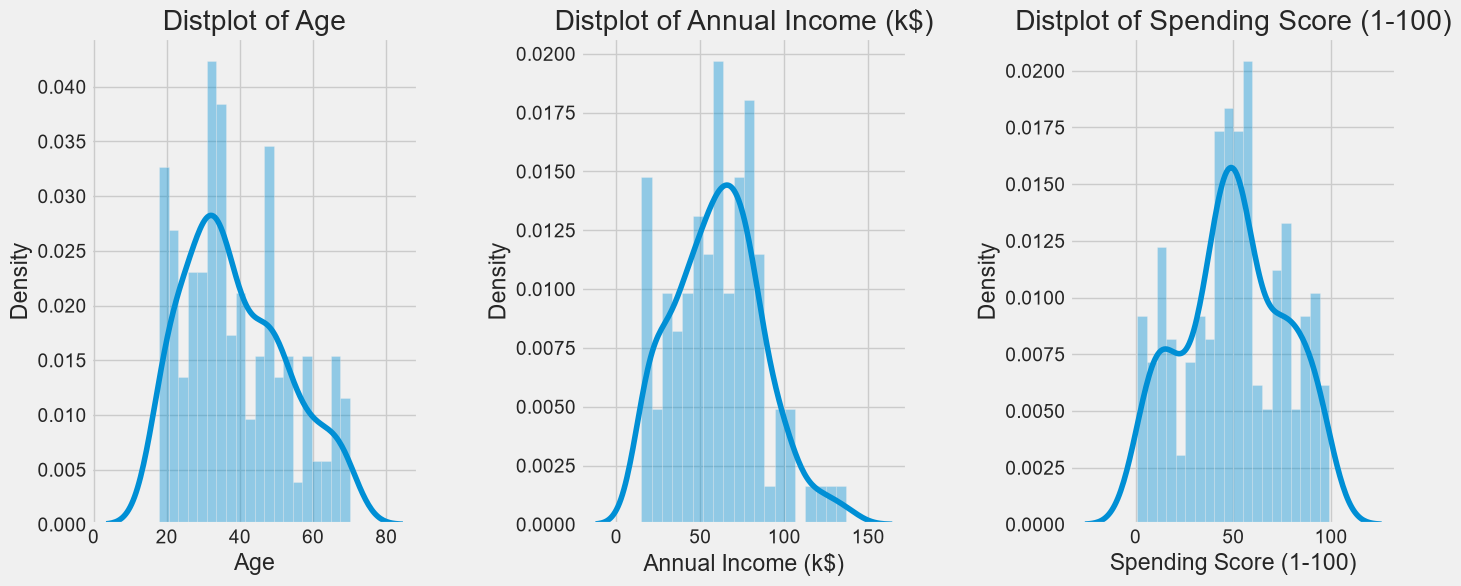

In [12]:
print("NguyenDucTinh - 6451071077")

plt.style.use('fivethirtyeight')

plt.figure(1, figsize=(15, 6))

n = 0

for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1

    plt.subplot(1, 3, n)

    plt.subplots_adjust(hspace=0.5, wspace=0.5)

    sns.distplot(data[x], bins=20)

    plt.title('Distplot of {}'.format(x))

plt.show()

## Câu 3: Thống kê số mẫu dữ liệu theo giới tính

NguyenDucTinh - 6451071077


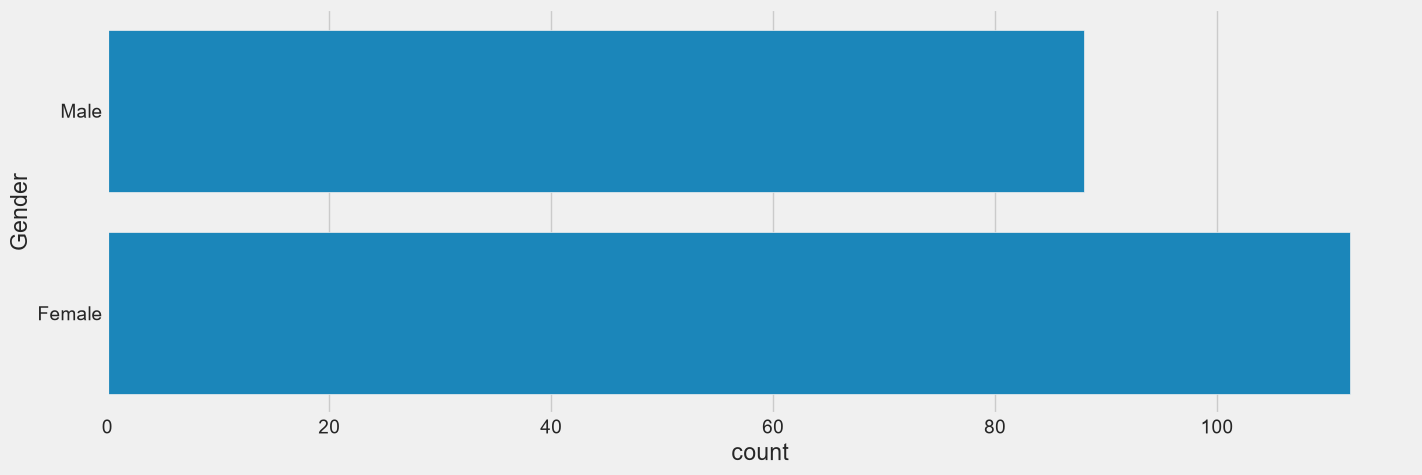

In [13]:
print("NguyenDucTinh - 6451071077")

plt.figure(1, figsize = (15, 5))
sns. countplot(y = 'Gender', data = data)
plt.show()

## Câu 4: Scatter Plot khảo sát Tuổi và Thu nhập hằng năm theo Giới tính

NguyenDucTinh - 6451071077


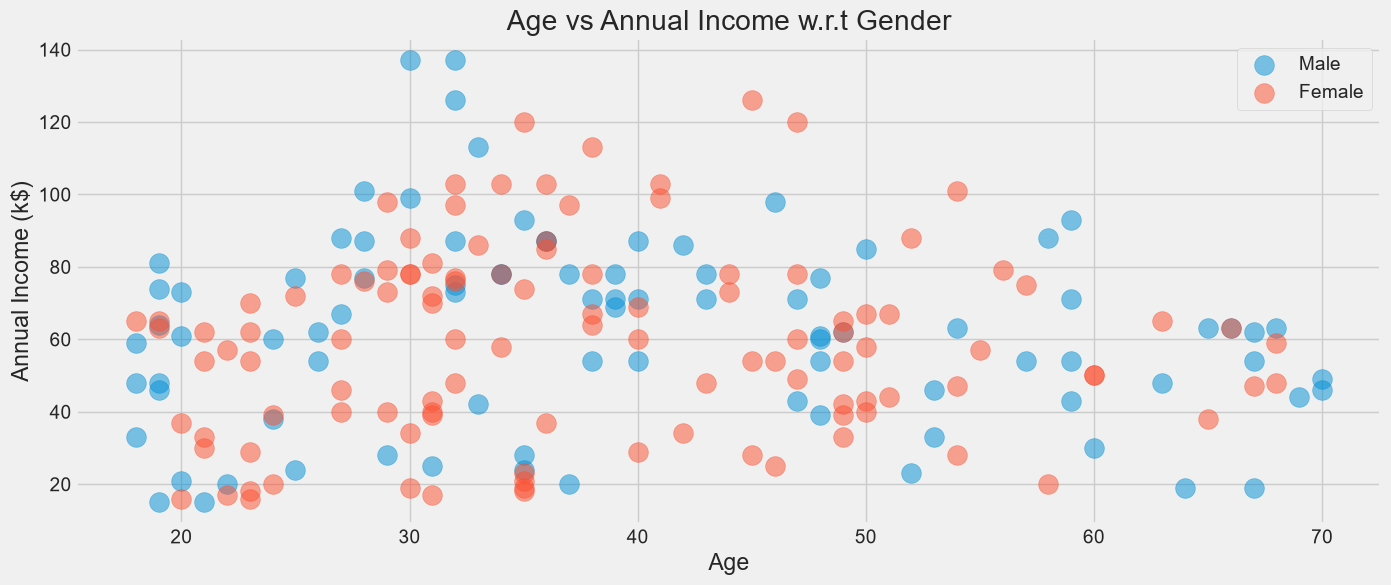

In [14]:
print("NguyenDucTinh - 6451071077")

plt.figure(1, figsize=(15, 6))

for gender in ['Male', 'Female']:
    plt.scatter(
        x='Age',
        y='Annual Income (k$)',
        data=data[data['Gender'] == gender],
        s=200,
        alpha=0.5,
        label=gender
    )

plt.xlabel('Age')
plt.ylabel('Annual Income (k$)')

plt.title('Age vs Annual Income w.r.t Gender')

plt.legend()
plt.show()

## Câu 5: Scatter Plot khảo sát Thu nhập và Điểm mua sắm theo Giới tính

NguyenDucTinh - 6451071077


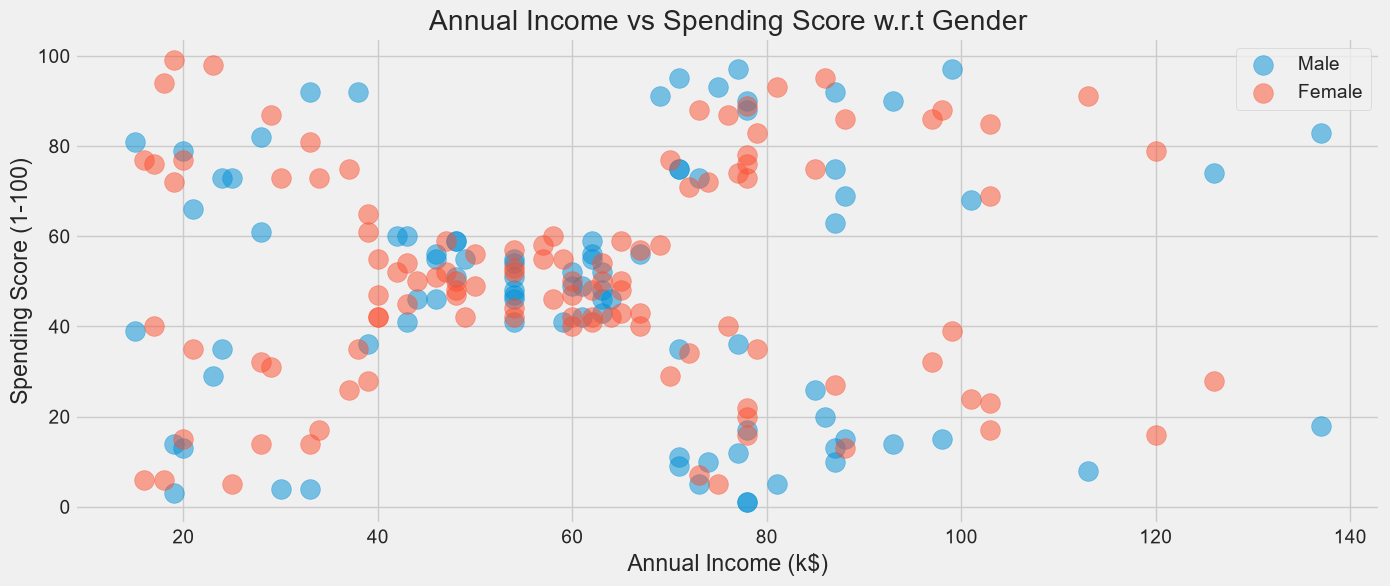

In [15]:
print("NguyenDucTinh - 6451071077")

plt.figure(1, figsize=(15, 6))

for gender in ['Male', 'Female']:
    plt.scatter(
        x='Annual Income (k$)',
        y='Spending Score (1-100)',
        data=data[data['Gender'] == gender],
        s=200,
        alpha=0.5,
        label=gender
    )

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.title('Annual Income vs Spending Score w.r.t Gender')

plt.legend()
plt.show()

## Câu 6: Gom cụm theo Tuổi và Điểm mua sắm

6.1 Sử dụng phương pháp Elbow Method

NguyenDucTinh - 6451071077


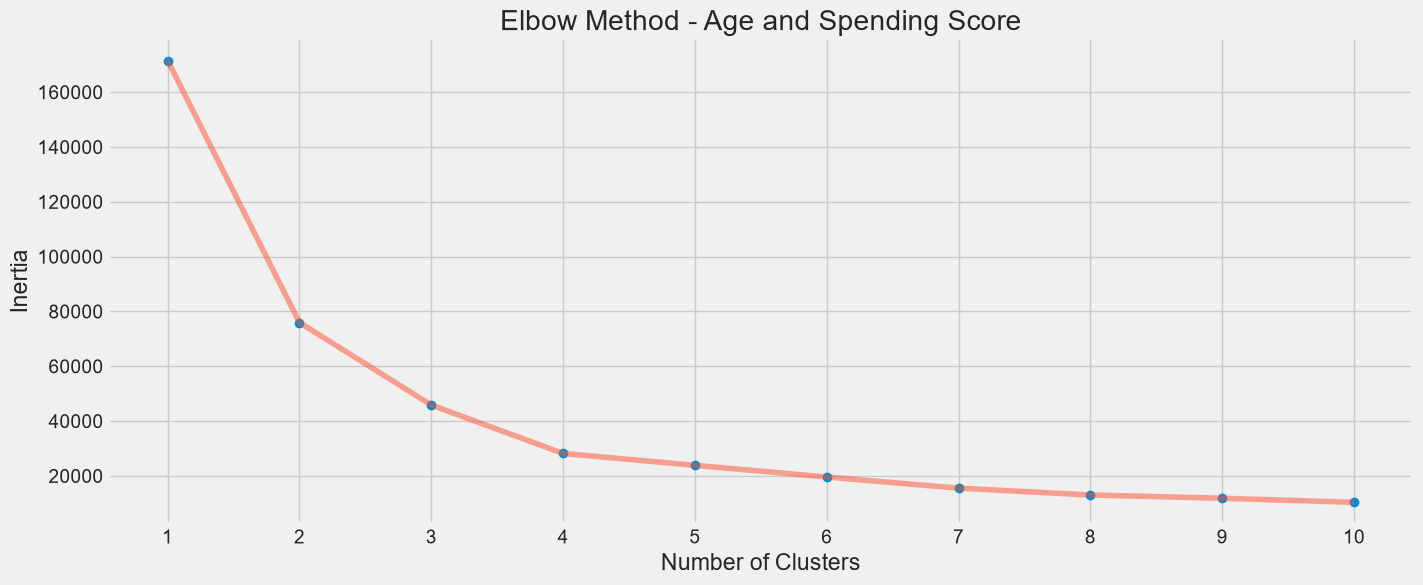

In [16]:
print("NguyenDucTinh - 6451071077")

# Chọn hai thuộc tính Age và Spending Score
X1 = data[['Age', 'Spending Score (1-100)']].iloc[:, :].values

# Danh sách lưu giá trị Inertia
inertia = []

# Khảo sát số cụm từ 1 đến 10
for n in range(1, 11):

    algorithm = KMeans(
        n_clusters=n,
        init='random',
        random_state=42,
        n_init=10
    )

    algorithm.fit(X1)

    inertia.append(algorithm.inertia_)

# Vẽ biểu đồ Elbow
plt.figure(1, figsize=(15, 6))

plt.plot(np.arange(1, 11), inertia, 'o')

plt.plot(
    np.arange(1, 11),
    inertia,
    '-',
    alpha=0.5
)

plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method - Age and Spending Score')

plt.xticks(np.arange(1, 11))

plt.grid(True)
plt.show()

6.2 Tiến hành gom cụm K-Means với k = 4

In [17]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo thuật toán K-Means với 4 cụm
algorithm = KMeans(
    n_clusters=4,
    init='random',
    random_state=42,
    n_init=10
)

# Huấn luyện mô hình
algorithm.fit(X1)

# Lấy nhãn cụm của từng khách hàng
labels1 = algorithm.labels_

# Lấy tọa độ tâm của các cụm
centroids1 = algorithm.cluster_centers_

# Hiển thị nhãn cụm
print("Nhãn cụm của từng khách hàng:")
print(labels1)

# Hiển thị tâm các cụm
print("\nTọa độ tâm các cụm:")
print(centroids1)

# Thêm nhãn cụm vào dữ liệu
data['label1'] = labels1

print("\nSố lượng khách hàng trong từng cụm:")
print(data['label1'].value_counts().sort_index())

NguyenDucTinh - 6451071077
Nhãn cụm của từng khách hàng:
[2 3 1 3 2 3 1 3 1 3 1 3 1 3 1 3 2 2 1 3 2 3 1 3 1 3 1 2 1 3 1 3 1 3 1 3 1
 3 1 3 0 3 0 2 1 2 0 2 2 2 0 2 2 0 0 0 0 0 2 0 0 2 0 0 0 2 0 0 2 2 0 0 0 0
 0 2 0 2 2 0 0 2 0 0 2 0 0 2 2 0 0 2 0 2 2 2 0 2 0 2 2 0 0 2 0 2 0 0 0 0 0
 2 2 2 2 2 0 0 0 0 2 2 2 3 2 3 0 3 1 3 1 3 2 3 1 3 1 3 1 3 1 3 2 3 1 3 0 3
 1 3 1 3 1 3 1 3 1 3 1 3 0 3 1 3 1 3 1 3 1 2 1 3 1 3 1 3 1 3 1 3 1 3 1 3 2
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3]

Tọa độ tâm các cụm:
[[55.70833333 48.22916667]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]
 [30.1754386  82.35087719]]

Số lượng khách hàng trong từng cụm:
label1
0    48
1    48
2    47
3    57
Name: count, dtype: int64


## Câu 7: Biểu diễn kết quả gom cụm

NguyenDucTinh - 6451071077


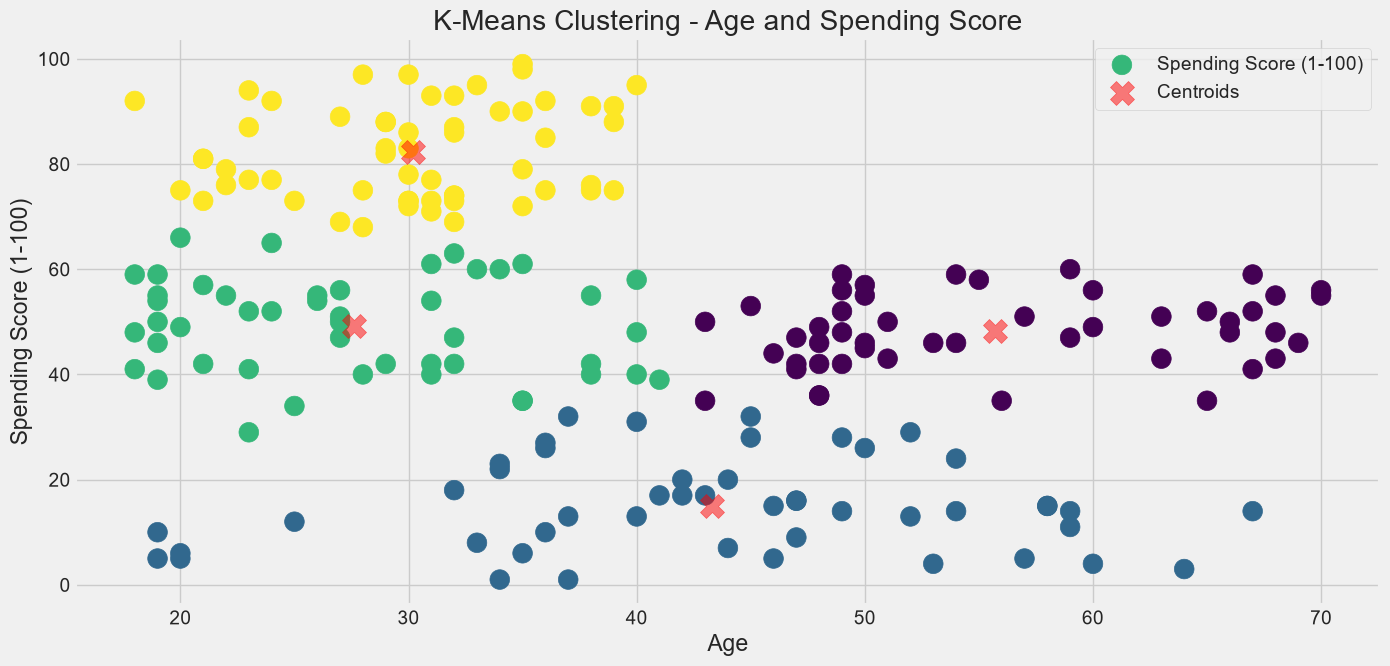

In [18]:
print("NguyenDucTinh - 6451071077")

plt.figure(1, figsize=(15, 7))

plt.clf()

# Biểu diễn các khách hàng theo nhãn cụm
plt.scatter(
    x='Age',
    y='Spending Score (1-100)',
    data=data,
    c=labels1,
    s=200,
    cmap='viridis'
)

# Biểu diễn tâm của các cụm
plt.scatter(
    x=centroids1[:, 0],
    y=centroids1[:, 1],
    s=300,
    c='red',
    alpha=0.5,
    marker='X',
    label='Centroids'
)

plt.ylabel('Spending Score (1-100)')
plt.xlabel('Age')

plt.title('K-Means Clustering - Age and Spending Score')

plt.legend()
plt.show()

## Câu 8: Đánh giá kết quả bằng Silhouette Coefficient

In [19]:
print("NguyenDucTinh - 6451071077")

# Tính hệ số Silhouette
silhouette1 = metrics.silhouette_score(
    X1,
    labels1,
    metric='euclidean'
)

print("Silhouette Coefficient:", silhouette1)

# Đánh giá kết quả
if silhouette1 >= 0.7:
    print("Kết quả phân cụm rất tốt.")
elif silhouette1 >= 0.5:
    print("Kết quả phân cụm tốt.")
elif silhouette1 >= 0.25:
    print("Kết quả phân cụm ở mức trung bình.")
else:
    print("Kết quả phân cụm chưa tốt.")

NguyenDucTinh - 6451071077
Silhouette Coefficient: 0.49973941540141753
Kết quả phân cụm ở mức trung bình.


## Câu 9: Gom cụm với các bộ thuộc tính khác

### PHẦN A – Gom cụm theo Thu nhập hằng năm và Điểm mua sắm

#### Sử dụng Elbow Method

NguyenDucTinh - 6451071077


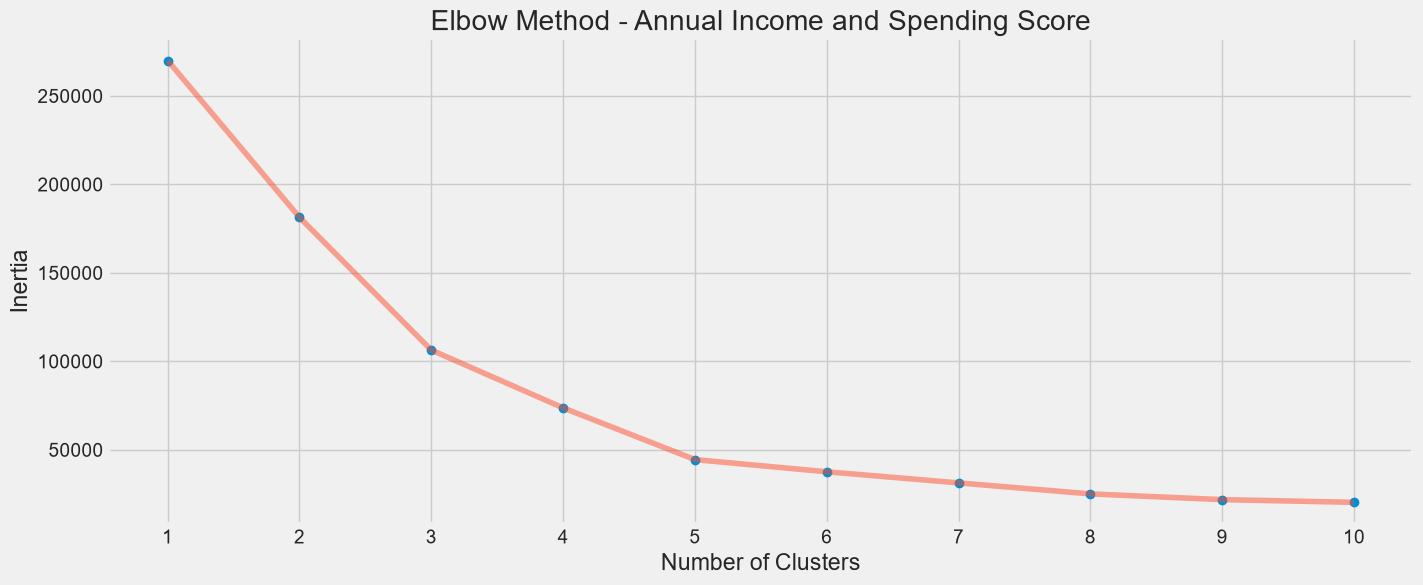

In [20]:
print("NguyenDucTinh - 6451071077")

# Chọn hai thuộc tính Annual Income và Spending Score
X2 = data[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].iloc[:, :].values

# Danh sách lưu giá trị Inertia
inertia2 = []

# Khảo sát số cụm từ 1 đến 10
for n in range(1, 11):

    algorithm2 = KMeans(
        n_clusters=n,
        init='random',
        random_state=42,
        n_init=10
    )

    algorithm2.fit(X2)

    inertia2.append(algorithm2.inertia_)

# Vẽ biểu đồ Elbow
plt.figure(figsize=(15, 6))

plt.plot(np.arange(1, 11), inertia2, 'o')

plt.plot(
    np.arange(1, 11),
    inertia2,
    '-',
    alpha=0.5
)

plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.title('Elbow Method - Annual Income and Spending Score')

plt.xticks(np.arange(1, 11))

plt.grid(True)
plt.show()

#### Tiến hành gom cụm K-Means

In [21]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo K-Means với 5 cụm
algorithm2 = KMeans(
    n_clusters=5,
    init='random',
    random_state=42,
    n_init=10
)

# Huấn luyện mô hình
algorithm2.fit(X2)

# Lấy nhãn cụm
labels2 = algorithm2.labels_

# Lấy tọa độ tâm cụm
centroids2 = algorithm2.cluster_centers_

# Lưu nhãn cụm vào dữ liệu
data['label2'] = labels2

print("Nhãn cụm:")
print(labels2)

print("\nTọa độ tâm cụm:")
print(centroids2)

print("\nSố lượng khách hàng trong từng cụm:")
print(data['label2'].value_counts().sort_index())

NguyenDucTinh - 6451071077
Nhãn cụm:
[0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0
 1 0 1 0 1 0 4 0 1 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 3 2 3 4 3 2 3 2 3 4 3 2 3 2 3 2 3 2 3 4 3 2 3 2 3
 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2
 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3]

Tọa độ tâm cụm:
[[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

Số lượng khách hàng trong từng cụm:
label2
0    23
1    22
2    35
3    39
4    81
Name: count, dtype: int64


#### Biểu diễn kết quả gom cụm

NguyenDucTinh - 6451071077


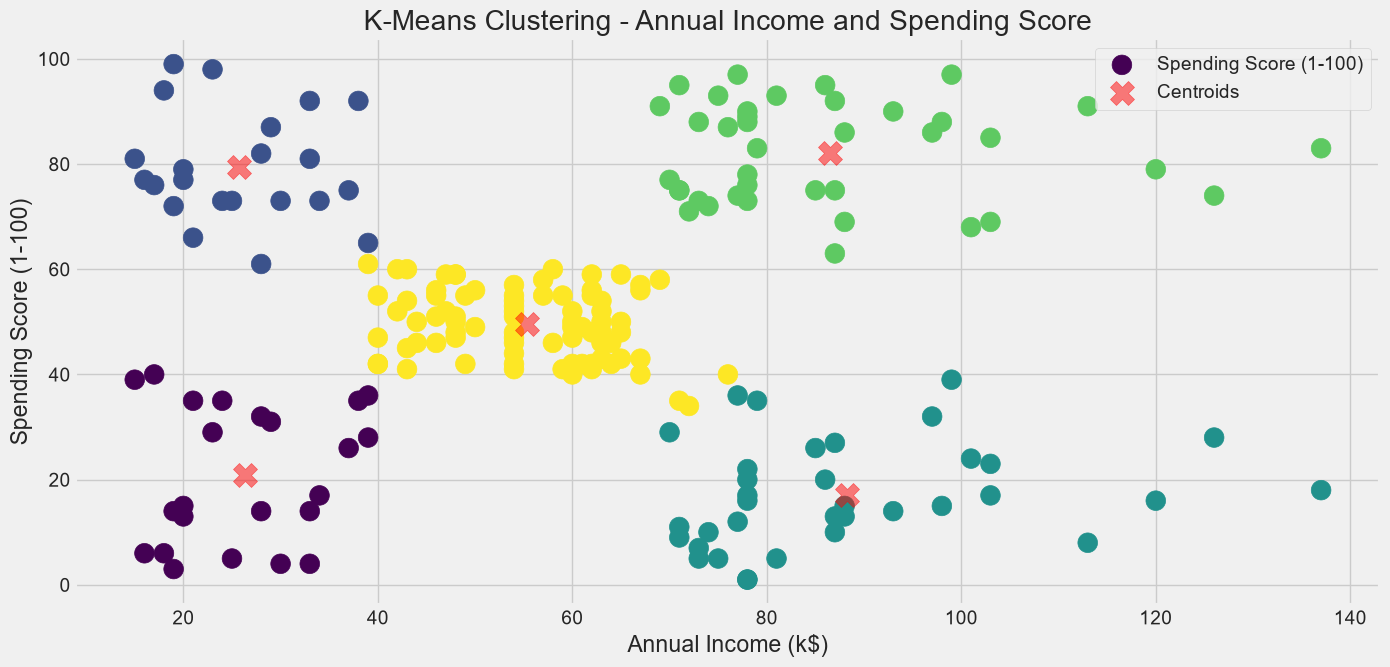

In [22]:
print("NguyenDucTinh - 6451071077")

plt.figure(figsize=(15, 7))

# Biểu diễn các điểm dữ liệu
plt.scatter(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    data=data,
    c=labels2,
    s=200,
    cmap='viridis'
)

# Biểu diễn tâm các cụm
plt.scatter(
    x=centroids2[:, 0],
    y=centroids2[:, 1],
    s=300,
    c='red',
    alpha=0.5,
    marker='X',
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.title('K-Means Clustering - Annual Income and Spending Score')

plt.legend()
plt.show()

#### Đánh giá bằng Silhouette Coefficient

In [23]:
print("NguyenDucTinh - 6451071077")

# Tính hệ số Silhouette
silhouette2 = metrics.silhouette_score(
    X2,
    labels2,
    metric='euclidean'
)

print("Silhouette Coefficient:", silhouette2)

# Đánh giá kết quả
if silhouette2 >= 0.7:
    print("Kết quả phân cụm rất tốt.")
elif silhouette2 >= 0.5:
    print("Kết quả phân cụm tốt.")
elif silhouette2 >= 0.25:
    print("Kết quả phân cụm ở mức trung bình.")
else:
    print("Kết quả phân cụm chưa tốt.")

NguyenDucTinh - 6451071077
Silhouette Coefficient: 0.553931997444648
Kết quả phân cụm tốt.


### PHẦN B – Gom cụm theo 3 thuộc tính và biểu diễn bằng biểu đồ 3D

#### Sử dụng Elbow Method

NguyenDucTinh - 6451071077


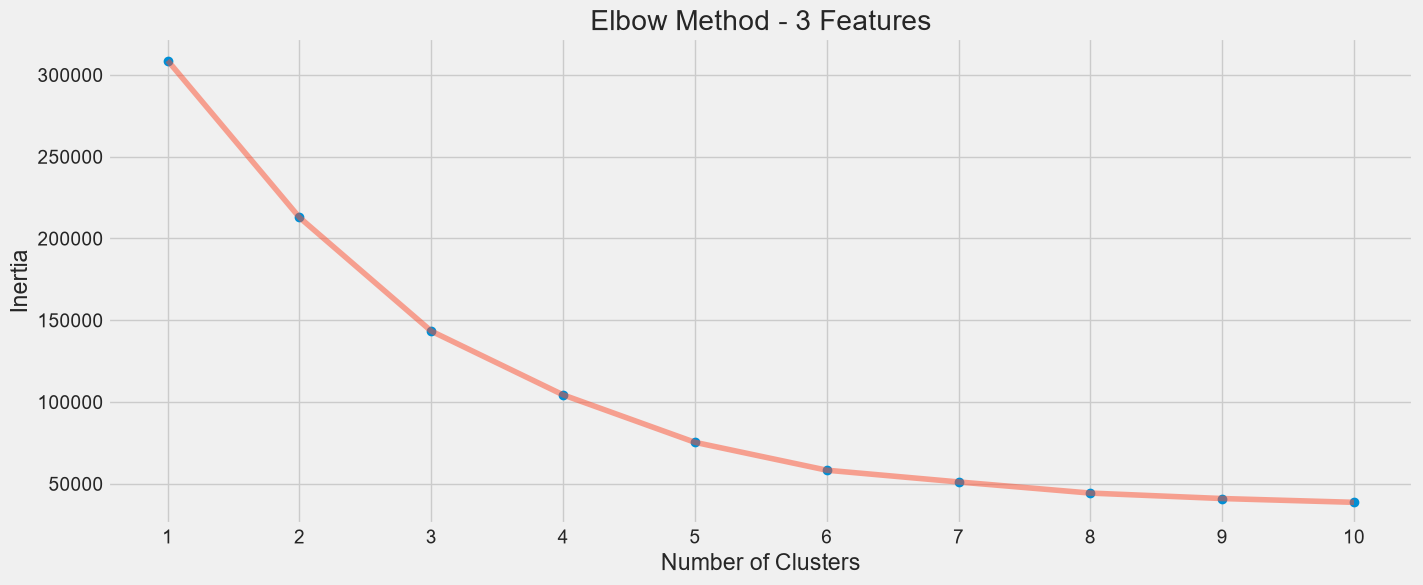

In [24]:
print("NguyenDucTinh - 6451071077")

# Chọn 3 thuộc tính Age, Annual Income và Spending Score
X3 = data[
    [
        'Age',
        'Annual Income (k$)',
        'Spending Score (1-100)'
    ]
].iloc[:, :].values

# Danh sách lưu giá trị Inertia
inertia3 = []

# Khảo sát số cụm từ 1 đến 10
for n in range(1, 11):

    algorithm3 = KMeans(
        n_clusters=n,
        init='random',
        random_state=42,
        n_init=10
    )

    algorithm3.fit(X3)

    inertia3.append(algorithm3.inertia_)

# Vẽ biểu đồ Elbow
plt.figure(figsize=(15, 6))

plt.plot(np.arange(1, 11), inertia3, 'o')

plt.plot(
    np.arange(1, 11),
    inertia3,
    '-',
    alpha=0.5
)

plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.title('Elbow Method - 3 Features')

plt.xticks(np.arange(1, 11))

plt.grid(True)
plt.show()

#### Tiến hành gom cụm K-Means với 3 thuộc tính

In [25]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo K-Means với 6 cụm
algorithm3 = KMeans(
    n_clusters=6,
    init='random',
    random_state=42,
    n_init=10
)

# Huấn luyện mô hình
algorithm3.fit(X3)

# Lấy nhãn cụm
labels3 = algorithm3.labels_

# Lấy tọa độ tâm cụm
centroids3 = algorithm3.cluster_centers_

# Lưu nhãn cụm vào dữ liệu
data['label3'] = labels3

print("Nhãn cụm:")
print(labels3)

print("\nTọa độ tâm cụm:")
print(centroids3)

print("\nSố lượng khách hàng trong từng cụm:")
print(data['label3'].value_counts().sort_index())

NguyenDucTinh - 6451071077
Nhãn cụm:
[0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0
 2 0 2 5 2 0 3 0 2 5 3 3 3 5 3 3 5 5 5 5 5 3 5 5 3 5 5 5 3 5 5 3 3 5 5 5 5
 5 3 5 3 3 5 5 3 5 5 3 5 5 3 3 5 5 3 5 3 3 3 5 3 5 3 3 5 5 3 5 3 5 5 5 5 5
 3 3 3 3 3 5 5 5 5 3 3 3 1 3 1 4 1 4 1 4 1 3 1 4 1 4 1 4 1 4 1 3 1 4 1 4 1
 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4
 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1]

Tọa độ tâm cụm:
[[44.31818182 25.77272727 20.27272727]
 [32.69230769 86.53846154 82.12820513]
 [25.27272727 25.72727273 79.36363636]
 [27.         56.65789474 49.13157895]
 [41.68571429 88.22857143 17.28571429]
 [56.34090909 53.70454545 49.38636364]]

Số lượng khách hàng trong từng cụm:
label3
0    22
1    39
2    22
3    38
4    35
5    44
Name: count, dtype: int64


#### Biểu diễn kết quả gom cụm bằng biểu đồ 3D

In [26]:
print("NguyenDucTinh - 6451071077")

# Tạo biểu đồ phân cụm 3D
trace1 = go.Scatter3d(

    # Trục X: Tuổi
    x=data['Age'],

    # Trục Y: Điểm mua sắm
    y=data['Spending Score (1-100)'],

    # Trục Z: Thu nhập hằng năm
    z=data['Annual Income (k$)'],

    mode='markers',

    marker=dict(

        # Màu sắc theo nhãn cụm
        color=data['label3'],

        # Kích thước điểm
        size=7,

        # Viền điểm dữ liệu
        line=dict(
            color=data['label3'],
            width=1
        ),

        opacity=0.8,

        colorscale='Viridis',

        colorbar=dict(
            title='Cluster'
        )
    )
)

# Tập hợp dữ liệu biểu đồ
dat = [trace1]

# Thiết lập bố cục
layout = go.Layout(

    title='K-Means Clustering - 3D',

    scene=dict(

        xaxis=dict(
            title='Age'
        ),

        yaxis=dict(
            title='Spending Score'
        ),

        zaxis=dict(
            title='Annual Income (k$)'
        )
    )
)

# Tạo biểu đồ
fig = go.Figure(
    data=dat,
    layout=layout
)

# Hiển thị biểu đồ 3D
fig.show()

NguyenDucTinh - 6451071077


#### Đánh giá kết quả bằng Silhouette Coefficient

In [27]:
print("NguyenDucTinh - 6451071077")

# Tính hệ số Silhouette cho 3 thuộc tính
silhouette3 = metrics.silhouette_score(
    X3,
    labels3,
    metric='euclidean'
)

print("Silhouette Coefficient:", silhouette3)

# Đánh giá kết quả
if silhouette3 >= 0.7:
    print("Kết quả phân cụm rất tốt.")
elif silhouette3 >= 0.5:
    print("Kết quả phân cụm tốt.")
elif silhouette3 >= 0.25:
    print("Kết quả phân cụm ở mức trung bình.")
else:
    print("Kết quả phân cụm chưa tốt.")

NguyenDucTinh - 6451071077
Silhouette Coefficient: 0.4523566166018854
Kết quả phân cụm ở mức trung bình.
